# 03 · Exploratory Data Analysis

Questions explored:
1. What do the property price and size distributions look like?
2. How do prices differ by city, state and city tier?
3. How do bedrooms, furnishing and new vs. resale affect price?
4. Which features are most related to price?

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

ROOT = Path('..')
IMG_DIR = ROOT / 'images'
IMG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMG_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()

df = pd.read_csv(ROOT / 'data/processed/magicbricks_cleaned.csv')
df['Price (Lakh)'] = df['Price'] / 1e5
print(df.shape)
df.describe().round(1).T

(2004, 21)


,count,mean,std,min,25%,50%,75%,max
Bedrooms,2004.0,2.5,0.9,1.0,2.0,2.0,3.0,7.0
Bathroom,2004.0,2.5,0.9,1.0,2.0,2.0,3.0,7.0
Area(sqft),2004.0,1310.7,841.8,242.0,774.8,1129.5,1575.8,10500.0
Parking,2004.0,0.7,0.8,0.0,0.0,1.0,1.0,10.0
Latitude,1833.0,21.5,5.7,8.5,18.5,19.3,28.4,30.7
Longitude,1833.0,76.7,3.8,26.9,73.3,77.2,77.7,91.8
Price per sqft,2004.0,9182.7,8470.2,1761.0,4504.8,6375.0,10000.0,65385.0
Price,2004.0,11607425.1,14685328.0,920000.0,4680000.0,7170000.0,12725000.0,240000000.0
Price (Lakh),2004.0,116.1,146.9,9.2,46.8,71.7,127.2,2400.0


## 1. Distributions

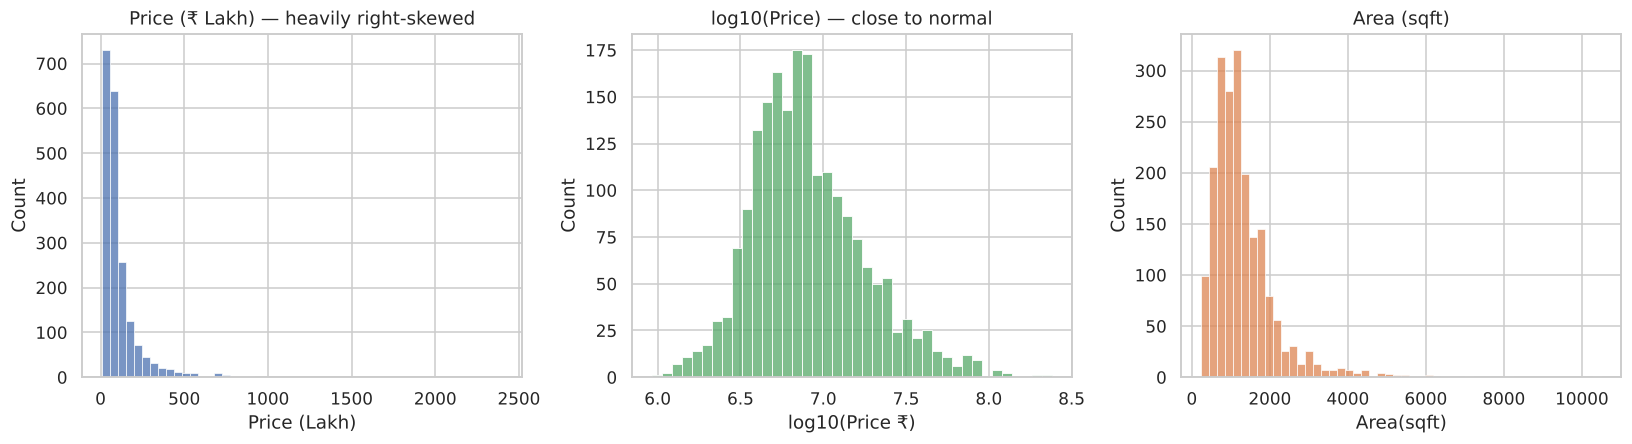

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.histplot(df['Price (Lakh)'], bins=50, ax=axes[0], color='#4C72B0')
axes[0].set_title('Price (₹ Lakh) — heavily right-skewed')
sns.histplot(np.log10(df['Price']), bins=40, ax=axes[1], color='#55A868')
axes[1].set_title('log10(Price) — close to normal'); axes[1].set_xlabel('log10(Price ₹)')
sns.histplot(df['Area(sqft)'], bins=50, ax=axes[2], color='#DD8452')
axes[2].set_title('Area (sqft)')
save(fig, 're_02_distributions')

**Observation:** prices are strongly right-skewed. The median is about ₹72 Lakh, but there is a long tail of luxury properties worth several crores. On a log scale the distribution is roughly normal, which is why the model predicts **log(price)**.

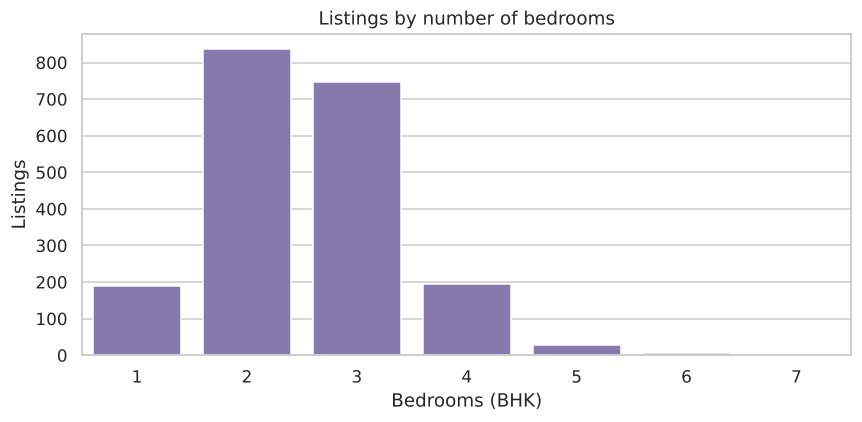

In [3]:
bed_counts = df['Bedrooms'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=bed_counts.index, y=bed_counts.values, ax=ax, color='#8172B3')
ax.set_xlabel('Bedrooms (BHK)'); ax.set_ylabel('Listings'); ax.set_title('Listings by number of bedrooms')
save(fig, 're_03_bedroom_counts')

**Observation:** most listings are 2 BHK and 3 BHK flats, so the model will be most reliable for these.

## 2. Location

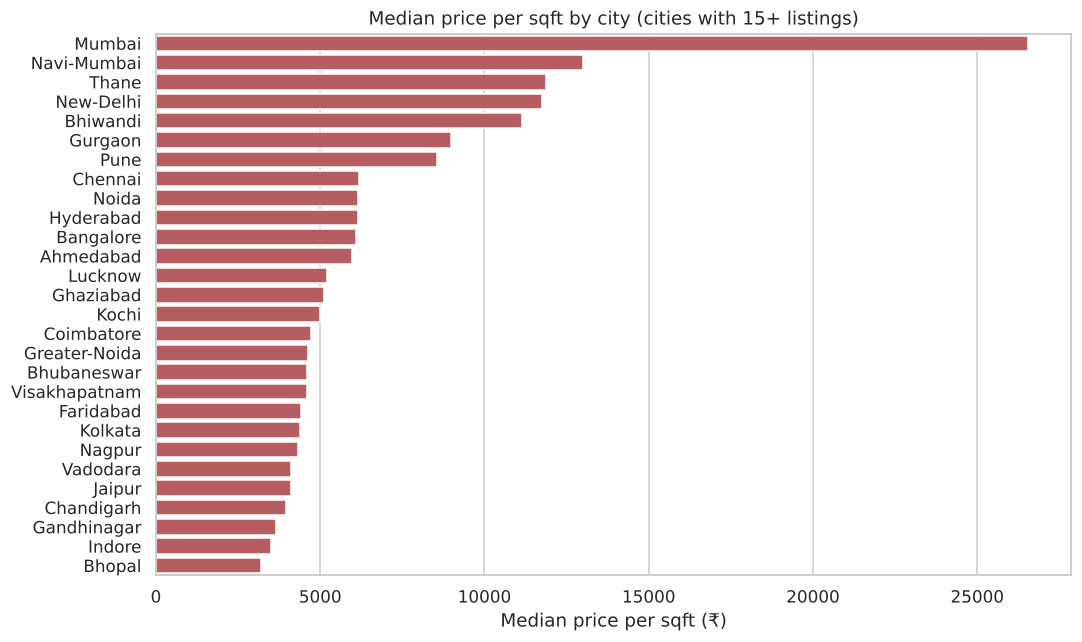

,listings,median_price_lakh,median_pps
City,,,
Mumbai,195,185.0,26538.0
Navi-Mumbai,41,82.0,13004.0
Thane,101,72.0,11875.0
New-Delhi,20,164.0,11762.0
Bhiwandi,18,56.0,11136.0
Gurgaon,101,160.0,8972.0
Pune,184,66.0,8552.0
Chennai,80,74.0,6194.0
Noida,149,76.0,6153.0


In [4]:
city_stats = (df.groupby('City').agg(listings=('Price', 'size'),
                                    median_price_lakh=('Price (Lakh)', 'median'),
                                    median_pps=('Price per sqft', 'median'))
              .query('listings >= 15').sort_values('median_pps', ascending=False))
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=city_stats['median_pps'], y=city_stats.index, ax=ax, color='#C44E52')
ax.set_xlabel('Median price per sqft (₹)'); ax.set_ylabel('')
ax.set_title('Median price per sqft by city (cities with 15+ listings)')
save(fig, 're_04_city_price_per_sqft')
city_stats.round(0).head(10)

**Observation:** Mumbai is in a league of its own at about ₹26,500/sqft, roughly double anywhere else. Next come the wider Mumbai region (Navi Mumbai, Thane, Bhiwandi) and New Delhi at ₹11,000–13,000/sqft, then Gurgaon and Pune. Comparing price **per sqft** instead of total price removes the effect of property size, so cities can be compared fairly.

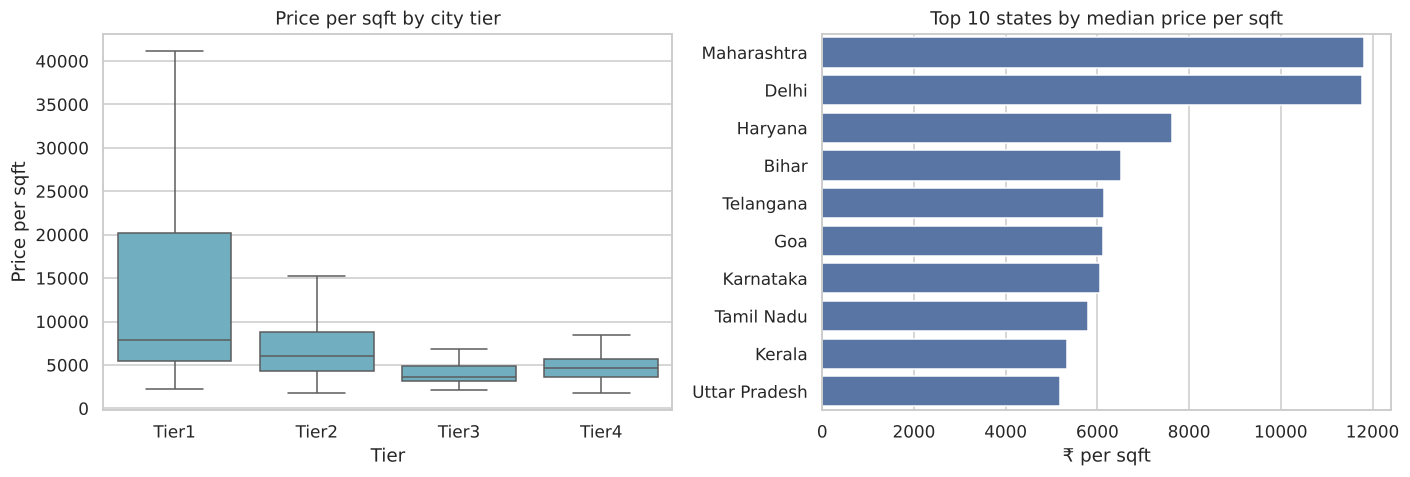

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = sorted(df['Tier'].unique())
sns.boxplot(data=df, x='Tier', y='Price per sqft', order=order, ax=axes[0], showfliers=False, color='#64B5CD')
axes[0].set_title('Price per sqft by city tier')
state = df.groupby('State/Territory')['Price per sqft'].median().sort_values(ascending=False).head(10)
sns.barplot(x=state.values, y=state.index, ax=axes[1], color='#4C72B0')
axes[1].set_title('Top 10 states by median price per sqft'); axes[1].set_xlabel('₹ per sqft'); axes[1].set_ylabel('')
save(fig, 're_05_tier_state')

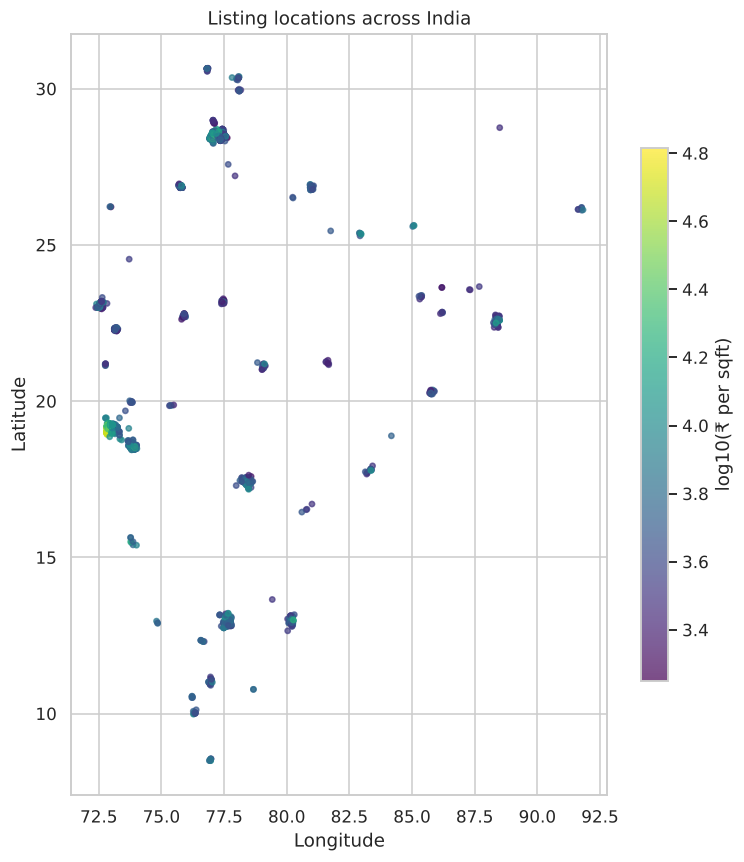

In [6]:
geo = df.dropna(subset=['Latitude', 'Longitude'])
geo = geo[geo['Latitude'].between(6, 37) & geo['Longitude'].between(68, 98)]
fig, ax = plt.subplots(figsize=(7, 8))
sc = ax.scatter(geo['Longitude'], geo['Latitude'], c=np.log10(geo['Price per sqft']), cmap='viridis', s=12, alpha=0.7)
cb = plt.colorbar(sc, ax=ax, shrink=0.7); cb.set_label('log10(₹ per sqft)')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_title('Listing locations across India')
save(fig, 're_06_geo_map')

**Observation:** after fixing the swapped coordinates, the listings line up with the locations of the Indian cities they belong to, clustered around the major metro regions. The highest prices per sqft (the brightest points) are concentrated around Mumbai.

## 3. Property attributes

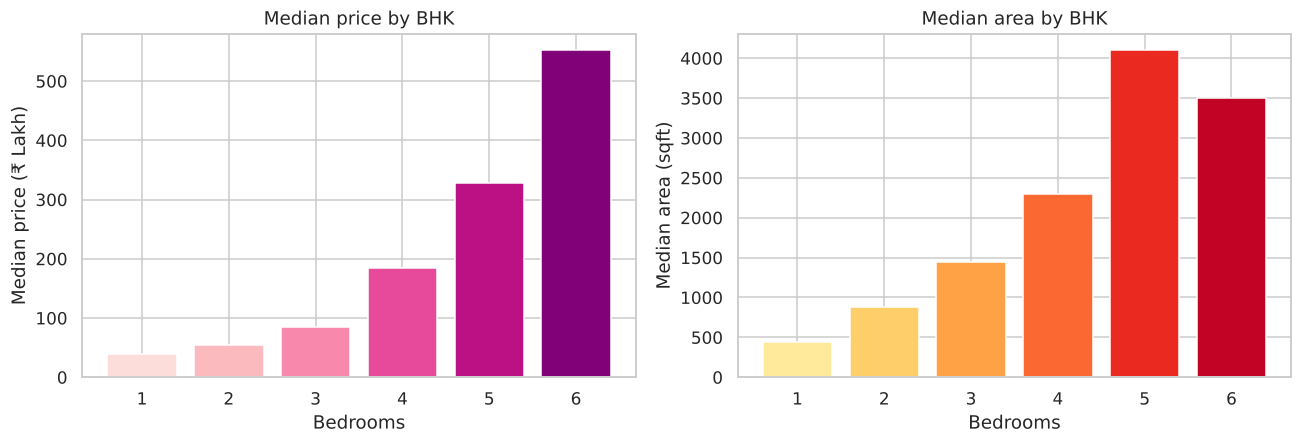

,Price (Lakh),Area(sqft)
Bedrooms,,
1,40.0,444.0
2,55.0,886.0
3,85.0,1440.0
4,184.0,2303.0
5,328.0,4102.0
6,552.0,3500.0


In [7]:
bed = df[df['Bedrooms'] <= 6].groupby('Bedrooms')[['Price (Lakh)', 'Area(sqft)']].median()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(bed.index, bed['Price (Lakh)'], color=sns.color_palette('RdPu', len(bed)))
axes[0].set_xlabel('Bedrooms'); axes[0].set_ylabel('Median price (₹ Lakh)'); axes[0].set_title('Median price by BHK')
axes[1].bar(bed.index, bed['Area(sqft)'], color=sns.color_palette('YlOrRd', len(bed)))
axes[1].set_xlabel('Bedrooms'); axes[1].set_ylabel('Median area (sqft)'); axes[1].set_title('Median area by BHK')
save(fig, 're_07_bhk_price_area')
bed.round(0)

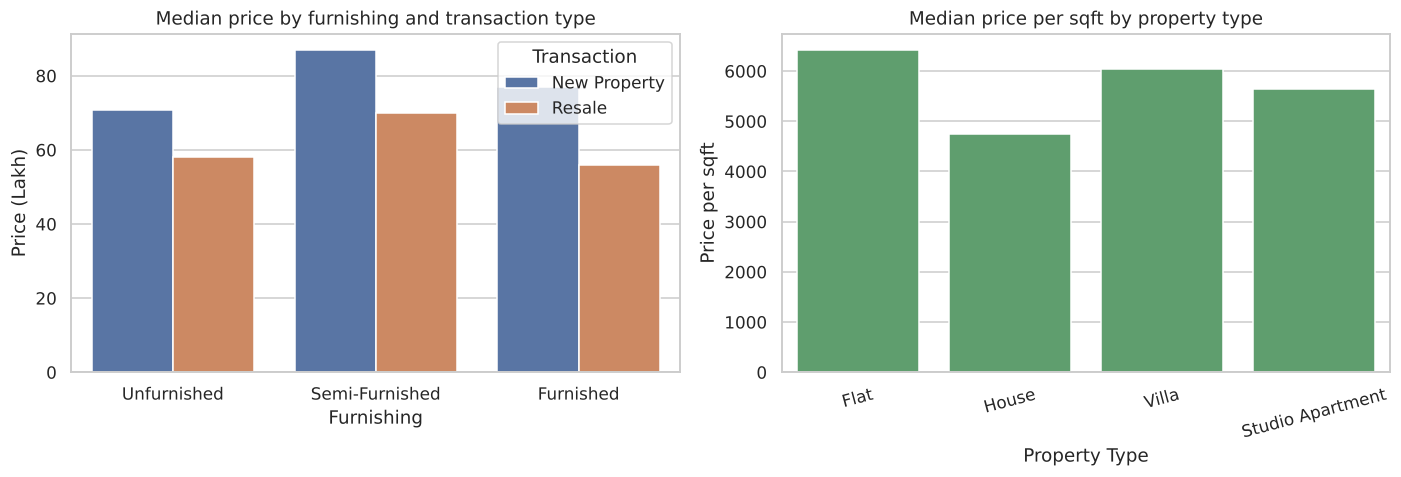

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=df, x='Furnishing', y='Price (Lakh)', hue='Transaction', estimator='median', errorbar=None,
            order=['Unfurnished', 'Semi-Furnished', 'Furnished'], ax=axes[0])
axes[0].set_title('Median price by furnishing and transaction type')
sns.barplot(data=df, x='Property Type', y='Price per sqft', estimator='median', errorbar=None, ax=axes[1], color='#55A868')
axes[1].set_title('Median price per sqft by property type'); axes[1].tick_params(axis='x', rotation=15)
save(fig, 're_08_furnishing_type')

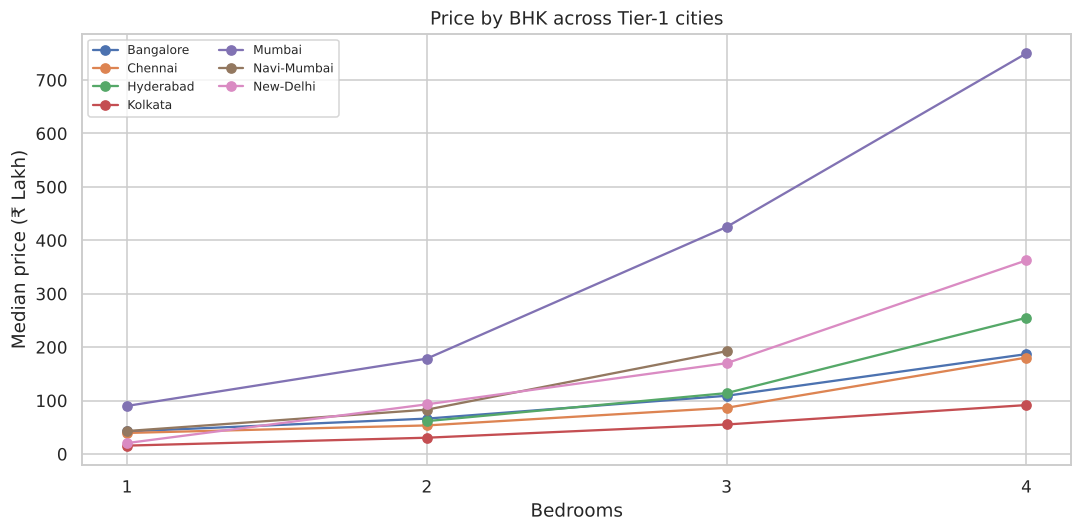

City,Bangalore,Chennai,Hyderabad,Kolkata,Mumbai,Navi-Mumbai,New-Delhi
Bedrooms,,,,,,,
1,42.0,39.0,NaN,16.0,90.0,43.0,20.0
2,66.0,54.0,62.0,30.0,178.0,83.0,93.0
3,109.0,86.0,114.0,55.0,425.0,192.0,170.0
4,187.0,180.0,255.0,92.0,750.0,NaN,362.0


In [9]:
tier1 = df[(df['Tier'] == 'Tier1') & df['Bedrooms'].between(1, 4)]
pivot = tier1.pivot_table(index='Bedrooms', columns='City', values='Price (Lakh)', aggfunc='median')
fig, ax = plt.subplots(figsize=(10, 5))
pivot.plot(marker='o', ax=ax)
ax.set_ylabel('Median price (₹ Lakh)'); ax.set_xticks([1, 2, 3, 4])
ax.set_title('Price by BHK across Tier-1 cities'); ax.legend(ncol=2, fontsize=8)
save(fig, 're_09_tier1_bhk_lines')
pivot.round(0)

## 4. Correlations

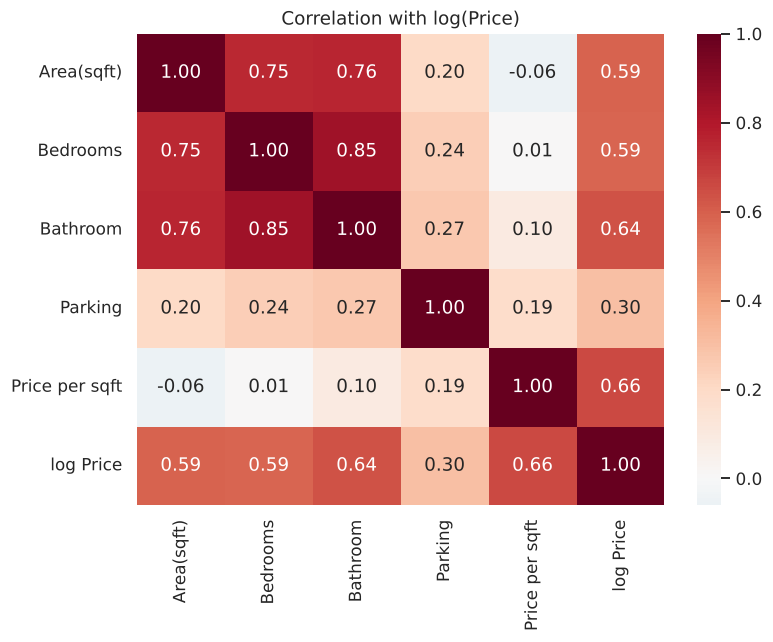

In [10]:
num = df[['Price', 'Area(sqft)', 'Bedrooms', 'Bathroom', 'Parking', 'Price per sqft']].copy()
num['log Price'] = np.log(num.pop('Price'))
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlation with log(Price)')
save(fig, 're_10_correlation')

## Key EDA takeaways

1. **Location matters most.** Mumbai's median price per sqft (~₹26,500) is about double that of any other city. Tier-1 cities (median ~₹7,900/sqft) cost more than Tier-2 (~₹6,000) and smaller cities (~₹3,700–4,700).
2. **Size drives the total price.** Bathrooms (0.64), area (0.59) and bedrooms (0.59) correlate strongly with log(price). The median price jumps from ₹55 Lakh for a 2 BHK to ₹85 Lakh for a 3 BHK and ₹184 Lakh for a 4 BHK.
3. **New properties list higher than resale**, and **semi-furnished** homes carry the highest median price in both groups. Fully furnished homes show little premium over unfurnished.
4. **Prices are log-normal.** Modelling log(price) keeps luxury listings from dominating the error.